# 01. DATA UNDERSTANDING — UAV-FD

## Mục tiêu nghiên cứu
Phát hiện lỗi cánh quạt UAV từ dữ liệu cảm biến IMU
nhằm hỗ trợ công tác kiểm tra bảo trì.

## Mục tiêu Data Understanding
1. Kiểm tra 18 file dữ liệu UAV-FD.
2. Tìm hiểu cấu trúc dữ liệu cảm biến IMU.
3. Kiểm tra số lượng và chất lượng dữ liệu.
4. Xác định các biến đầu vào và nhãn phân loại.
5. Chuẩn bị dữ liệu cho EDA và Feature Engineering.

## Bài toán
Binary Classification:
- Normal = 0
- Fault = 1


In [6]:

# kiểm tra số lượng file
normal_files = sorted(NORMAL_DIR.glob("*.mat"))
fault_files = sorted(FAULT_DIR.glob("*.mat"))

print("Số file Normal:", len(normal_files))
print("Số file Fault:", len(fault_files))
print("Tổng số file:", len(normal_files) + len(fault_files))

assert len(normal_files) == 6, "Số file Normal không đúng!"
assert len(fault_files) == 12, "Số file Fault không đúng!"


Số file Normal: 6
Số file Fault: 12
Tổng số file: 18


In [5]:

import pandas as pd
import numpy as np
from scipy.io import loadmat
from pathlib import Path
import matplotlib.pyplot as plt



# Giả sử VS Code mở tại thư mục gốc DTA301_UAV
DATA_DIR = Path("../data/raw")

NORMAL_DIR = DATA_DIR / "normal"
FAULT_DIR = DATA_DIR / "fault"

print("Thư mục làm việc:", Path.cwd())
print("Normal tồn tại:", NORMAL_DIR.exists())
print("Fault tồn tại:", FAULT_DIR.exists())


Thư mục làm việc: c:\Users\DELL\OneDrive\Desktop\DTA301_RBL\notebooks
Normal tồn tại: True
Fault tồn tại: True


In [7]:

expected_normal = {
    f"NO_FAULT{i}.mat"
    for i in range(1, 7)
}

expected_fault = {
    f"FAULT_M{i}_{level}.mat"
    for i in range(1, 7)
    for level in (5, 10)
}

actual_normal = {p.name for p in normal_files}
actual_fault = {p.name for p in fault_files}

assert actual_normal == expected_normal, (
    "Danh sách file Normal không đúng!"
)

assert actual_fault == expected_fault, (
    "Danh sách file Fault không đúng!"
)

file_info = []

for path in normal_files:
    file_info.append({
        "file_name": path.name,
        "label": 0,
        "status": "Normal"
    })

for path in fault_files:
    file_info.append({
        "file_name": path.name,
        "label": 1,
        "status": "Fault"
    })

df_files = pd.DataFrame(file_info)

display(df_files)


,file_name,label,status
0,NO_FAULT1.mat,0,Normal
1,NO_FAULT2.mat,0,Normal
2,NO_FAULT3.mat,0,Normal
3,NO_FAULT4.mat,0,Normal
4,NO_FAULT5.mat,0,Normal
5,NO_FAULT6.mat,0,Normal
6,FAULT_M1_10.mat,1,Fault
7,FAULT_M1_5.mat,1,Fault
8,FAULT_M2_10.mat,1,Fault
9,FAULT_M2_5.mat,1,Fault


In [8]:

sample_path = NORMAL_DIR / "NO_FAULT1.mat"

data = loadmat(sample_path)

print("Các biến trong file MATLAB:")

for key in data.keys():
    if not key.startswith("__"):
        value = data[key]

        print(
            f"{key:20s}",
            "Shape:", getattr(value, "shape", None)
        )


Các biến trong file MATLAB:
FMT_label            Shape: (6, 1)
UNIT_label           Shape: (4, 1)
FMTU_label           Shape: (5, 1)
MULT_label           Shape: (4, 1)
GPS_label            Shape: (16, 1)
GPA_label            Shape: (12, 1)
UBX1_label           Shape: (8, 1)
UBX2_label           Shape: (7, 1)
GRAW_label           Shape: (12, 1)
GRXH_label           Shape: (7, 1)
GRXS_label           Shape: (14, 1)
SBPH_label           Shape: (5, 1)
SBRH_label           Shape: (9, 1)
SBRM_label           Shape: (16, 1)
SBRE_label           Shape: (7, 1)
MSG_label            Shape: (3, 1)
RCIN_label           Shape: (16, 1)
RCI2_label           Shape: (5, 1)
RCOU_label           Shape: (16, 1)
RCO2_label           Shape: (6, 1)
RCO3_label           Shape: (16, 1)
RSSI_label           Shape: (4, 1)
BARO_label           Shape: (11, 1)
PL_label             Shape: (14, 1)
POWR_label           Shape: (11, 1)
CMD_label            Shape: (13, 1)
MAVC_label           Shape: (17, 1)
RAD_label     

c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\scipy\io\matlab\_mio.py:242: MatReadWarning: Duplicate variable name "s?????_label" in stream - replacing previous with new
Considerscipy.io.matlab.varmats_from_mat to split file into single variable files
  matfile_dict = MR.get_variables(variable_names)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\scipy\io\matlab\_mio.py:242: MatReadWarning: Duplicate variable name "s--_label" in stream - replacing previous with new
Considerscipy.io.matlab.varmats_from_mat to split file into single variable files
  matfile_dict = MR.get_variables(variable_names)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\scipy\io\matlab\_mio.py:242: MatReadWarning: Duplicate variable name "s---_label" in stream - replacing previous with new
Considerscipy.io.matlab.varmats_from_mat to split file into single variable files
  matfile_dict = MR.get_variables(variable_names)
c:\Users\DELL\AppData

In [10]:

def clean_label(x):
    while isinstance(x, np.ndarray):
        x = x.item()
    return str(x).strip()

imu_labels = [
    clean_label(x)
    for x in data["IMU_label"].flatten()
]

print("Tên các cột IMU:")

for index, name in enumerate(imu_labels):
    print(index, ":", name)


Tên các cột IMU:
0 : LineNo
1 : TimeUS
2 : I
3 : GyrX
4 : GyrY
5 : GyrZ
6 : AccX
7 : AccY
8 : AccZ
9 : EG
10 : EA
11 : T
12 : GH
13 : AH
14 : GHz
15 : AHz


In [11]:

selected_columns = [
    "TimeUS",
    "AccX", "AccY", "AccZ",
    "GyrX", "GyrY", "GyrZ"
]

all_dfs = []
file_summary = []

for label, paths in [
    (0, normal_files),
    (1, fault_files)
]:
    for path in paths:

        mat = loadmat(path)

        if "IMU_0" not in mat:
            raise KeyError(f"{path.name} thiếu IMU_0")

        if "IMU_label" not in mat:
            raise KeyError(f"{path.name} thiếu IMU_label")

        labels = [
            clean_label(x)
            for x in mat["IMU_label"].flatten()
        ]

        imu = mat["IMU_0"]

        if imu.shape[1] != len(labels):
            raise ValueError(
                f"{path.name}: số cột và tên cột không khớp"
            )

        df = pd.DataFrame(imu, columns=labels)

        missing_columns = (
            set(selected_columns) - set(df.columns)
        )

        if missing_columns:
            raise ValueError(
                f"{path.name} thiếu cột: {missing_columns}"
            )

        df = df[selected_columns].copy()

        df["source_file"] = path.name
        df["Label"] = label

        all_dfs.append(df)

        file_summary.append({
            "file_name": path.name,
            "label": label,
            "n_rows": len(df),
            "n_columns_imu": imu.shape[1]
        })

df_uav = pd.concat(
    all_dfs,
    ignore_index=True
)

df_summary = pd.DataFrame(file_summary)

display(df_summary)
display(df_uav.head())


,file_name,label,n_rows,n_columns_imu
0,NO_FAULT1.mat,0,26162,16
1,NO_FAULT2.mat,0,57456,16
2,NO_FAULT3.mat,0,42977,16
3,NO_FAULT4.mat,0,36855,16
4,NO_FAULT5.mat,0,34790,16
5,NO_FAULT6.mat,0,37880,16
6,FAULT_M1_10.mat,1,47019,16
7,FAULT_M1_5.mat,1,64276,16
8,FAULT_M2_10.mat,1,53865,16
9,FAULT_M2_5.mat,1,39209,16


,TimeUS,AccX,AccY,AccZ,GyrX,GyrY,GyrZ,source_file,Label
0,15037020.0,-0.228946,0.251855,-9.755047,0.002102,-0.003518,-0.002962,NO_FAULT1.mat,0
1,15039579.0,-0.230974,0.247798,-9.754610,0.001381,-0.002813,-0.001937,NO_FAULT1.mat,0
2,15071017.0,-0.236723,0.239819,-9.790745,0.001758,0.000215,0.000723,NO_FAULT1.mat,0
3,15073159.0,-0.234398,0.239244,-9.795955,0.000414,-0.000258,0.000247,NO_FAULT1.mat,0
4,15090845.0,-0.222734,0.259719,-9.768929,0.003893,0.001428,0.000665,NO_FAULT1.mat,0


In [12]:

print("Kích thước dữ liệu:", df_uav.shape)

print("\nKiểu dữ liệu:")
df_uav.info()

print("\nSố mẫu theo nhãn:")
print(df_uav["Label"].value_counts())


Kích thước dữ liệu: (767763, 9)

Kiểu dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 767763 entries, 0 to 767762
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   TimeUS       767763 non-null  float64
 1   AccX         767763 non-null  float64
 2   AccY         767763 non-null  float64
 3   AccZ         767763 non-null  float64
 4   GyrX         767763 non-null  float64
 5   GyrY         767763 non-null  float64
 6   GyrZ         767763 non-null  float64
 7   source_file  767763 non-null  str    
 8   Label        767763 non-null  int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 52.7 MB

Số mẫu theo nhãn:
Label
1    531643
0    236120
Name: count, dtype: int64


In [13]:

numeric_columns = selected_columns

quality_rows = []

for file_name, group in df_uav.groupby("source_file"):

    values = group[numeric_columns].to_numpy()

    quality_rows.append({
        "file_name": file_name,
        "missing_values": int(
            group[numeric_columns].isna().sum().sum()
        ),
        "infinite_values": int(
            np.isinf(values).sum()
        ),
        "duplicate_time": int(
            group["TimeUS"].duplicated().sum()
        ),
        "non_increasing_time": int(
            (group["TimeUS"].diff().dropna() <= 0).sum()
        )
    })

df_quality = pd.DataFrame(quality_rows)

display(df_quality)


,file_name,missing_values,infinite_values,duplicate_time,non_increasing_time
0,FAULT_M1_10.mat,0,0,0,0
1,FAULT_M1_5.mat,0,0,0,0
2,FAULT_M2_10.mat,0,0,0,0
3,FAULT_M2_5.mat,0,0,0,0
4,FAULT_M3_10.mat,0,0,0,0
5,FAULT_M3_5.mat,0,0,0,0
6,FAULT_M4_10.mat,0,0,0,0
7,FAULT_M4_5.mat,0,0,0,0
8,FAULT_M5_10.mat,0,0,0,0
9,FAULT_M5_5.mat,0,0,0,0


In [14]:

time_summary = []

for file_name, group in df_uav.groupby("source_file"):

    time_us = group["TimeUS"]

    duration_seconds = (
        time_us.iloc[-1] - time_us.iloc[0]
    ) / 1_000_000

    intervals = time_us.diff().dropna()

    time_summary.append({
        "file_name": file_name,
        "duration_seconds": duration_seconds,
        "median_interval_us": intervals.median(),
        "max_interval_us": intervals.max()
    })

df_time = pd.DataFrame(time_summary)

display(df_time.round(3))


,file_name,duration_seconds,median_interval_us,max_interval_us
0,FAULT_M1_10.mat,134.824,2661.0,76481.0
1,FAULT_M1_5.mat,283.924,2625.0,59241738.0
2,FAULT_M2_10.mat,153.189,2653.0,82109.0
3,FAULT_M2_5.mat,110.139,2638.0,91805.0
4,FAULT_M3_10.mat,112.569,2668.0,106001.0
5,FAULT_M3_5.mat,303.211,2627.0,70546811.0
6,FAULT_M4_10.mat,103.437,2656.0,100861.0
7,FAULT_M4_5.mat,79.345,2668.0,148323.0
8,FAULT_M5_10.mat,124.997,2663.0,120628.0
9,FAULT_M5_5.mat,90.500,2637.0,89894.0


In [15]:

features = [
    "AccX", "AccY", "AccZ",
    "GyrX", "GyrY", "GyrZ"
]

print("Thống kê toàn bộ dữ liệu:")
display(df_uav[features].describe().T.round(4))

print("Thống kê theo trạng thái:")
display(
    df_uav.groupby("Label")[features]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


Thống kê toàn bộ dữ liệu:


,count,mean,std,min,25%,50%,75%,max
AccX,767763.0,-0.1051,1.1843,-9.9454,-0.4264,-0.1932,0.0618,11.8988
AccY,767763.0,0.2439,1.7979,-14.1028,0.0850,0.5247,0.9099,12.9277
AccZ,767763.0,-9.4335,1.5728,-29.8981,-9.8655,-9.7418,-9.5727,3.9378
GyrX,767763.0,0.0025,0.2358,-2.4418,-0.0648,-0.0002,0.0657,3.0693
GyrY,767763.0,0.0056,0.2111,-2.9700,-0.0535,0.0001,0.0577,2.8171
GyrZ,767763.0,0.0040,0.1932,-2.6253,-0.0329,-0.0002,0.0334,2.7906


Thống kê theo trạng thái:


AccX                             AccY                            \
         mean     std     min      max    mean     std      min      max   
Label                                                                      
0     -0.0705  1.3516 -9.9454  11.2190  0.3094  1.4627 -12.9643  12.4943   
1     -0.1205  1.1015 -8.5873  11.8988  0.2148  1.9274 -14.1028  12.9277   

         AccZ          ...    GyrX            GyrY                          \
         mean     std  ...     min     max    mean     std     min     max   
Label                  ...                                                   
0     -9.4883  1.4094  ... -2.4418  2.2786  0.0083  0.2078 -2.0301  2.7183   
1     -9.4091  1.6396  ... -2.3330  3.0693  0.0044  0.2125 -2.9700  2.8171   

         GyrZ                          
         mean     std     min     max  
Label                                  
0     -0.0016  0.2005 -2.3405  2.0135  
1      0.0066  0.1898 -2.6253  2.7906  

[2 rows x 24 columns]

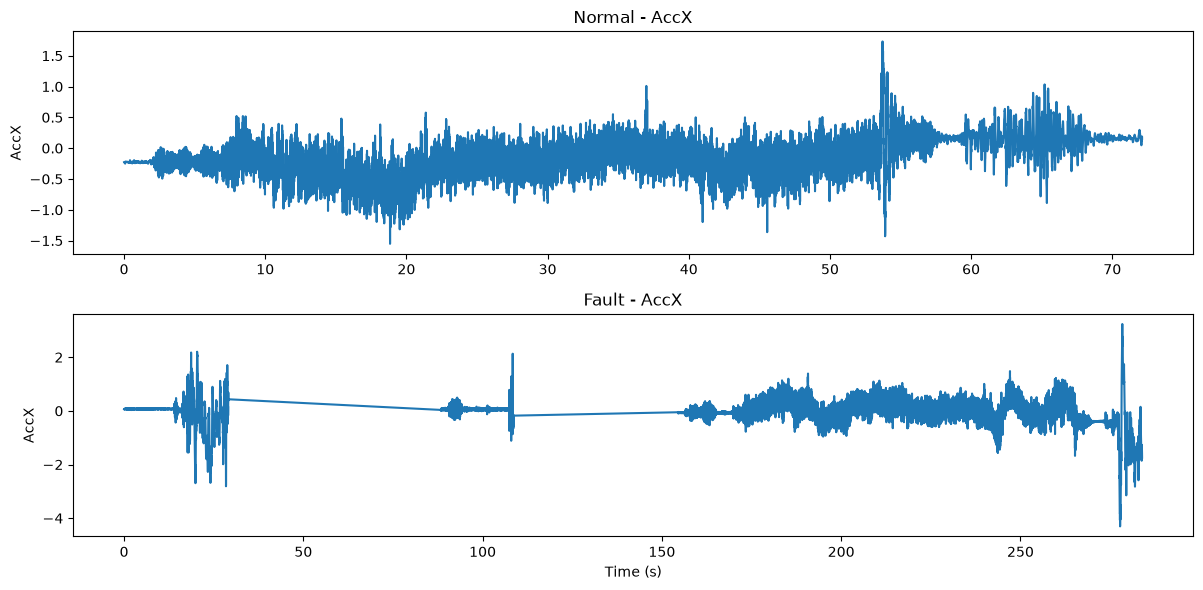

In [16]:

normal_sample = df_uav[
    df_uav["source_file"] == "NO_FAULT1.mat"
].copy()

fault_sample = df_uav[
    df_uav["source_file"] == "FAULT_M1_5.mat"
].copy()

# Chuyển về thời gian tương đối theo giây
normal_sample["Time_s"] = (
    normal_sample["TimeUS"]
    - normal_sample["TimeUS"].iloc[0]
) / 1_000_000

fault_sample["Time_s"] = (
    fault_sample["TimeUS"]
    - fault_sample["TimeUS"].iloc[0]
) / 1_000_000

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 6)
)

axes[0].plot(
    normal_sample["Time_s"],
    normal_sample["AccX"]
)
axes[0].set_title("Normal - AccX")
axes[0].set_ylabel("AccX")

axes[1].plot(
    fault_sample["Time_s"],
    fault_sample["AccX"]
)
axes[1].set_title("Fault - AccX")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("AccX")

plt.tight_layout()
plt.show()


In [17]:

from pathlib import Path

# Đường dẫn lưu file
output_path = Path("../data/processed/imu_combined.csv")

# Tạo thư mục processed nếu chưa có
output_path.parent.mkdir(parents=True, exist_ok=True)

# Lưu dữ liệu
df_uav.to_csv(output_path, index=False)

print("Đã tạo file tại:", output_path.resolve())


Đã tạo file tại: C:\Users\DELL\OneDrive\Desktop\DTA301_RBL\data\processed\imu_combined.csv
